# Pipeline de limpieza — Amazon Product Sales

**Objetivo:** dejar el dataset listo para modelar, con cada decisión justificada.

**Variable objetivo:** `bought_in_last_month` (compras en el último mes).

Esta libreta reproduce paso a paso (y documenta el *por qué*) los procesos que están
en `LIMPIEZA_DATOS.md

In [4]:
# Librerias
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)


## 0. Inventario inicial

Antes de transformar nada, describimos el estado del dataset: tamaño, nulos y cardinalidad
de cada columna. De aquí salen las decisiones de imputación y de exclusión de variables.

In [5]:
amazon_data = pd.read_csv("amazon_sales_data_uncleaned.csv")
print("Shape inicial: " + str(amazon_data.shape))
print("\nNulos por columna:")
print(amazon_data.isna().sum().to_string())
print("\nCardinalidad por columna:")
print(amazon_data.nunique().to_string())

Shape inicial: (42675, 16)

Nulos por columna:
Title                           0
Rating                       1024
Number_of_reviews            1024
bought_in_last_month         3217
Current/discounted_price    11749
Price_on_variant                0
Listed_price                    0
is_best_seller                  0
is_sponsored                    0
is_couponed                     0
buy_box_availability        14653
delivery_details            11720
sustainability_badges       39267
image_url                       0
product_url                  2069
collected_at                    0

Cardinalidad por columna:
Title                        8808
Rating                         31
Number_of_reviews            4413
bought_in_last_month           59
Current/discounted_price     2576
Price_on_variant             3466
Listed_price                  911
is_best_seller                 12
is_sponsored                    2
is_couponed                    42
buy_box_availability            1
delivery

In [6]:
amazon_data.head()

,Title,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,Price_on_variant,Listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6 out of 5 stars,375,300+ bought in past month,89.68,basic variant price: 2.4GHz,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact,https://m.media-amazon.com/images/I/71pAqiVEs3...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3 out of 5 stars,"2,457",6K+ bought in past month,9.99,basic variant price: nan,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN,https://m.media-amazon.com/images/I/61nbF6aVIP...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6 out of 5 stars,"3,044",2K+ bought in past month,314,basic variant price: nan,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/61h78MEXoj...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
3,"Apple AirPods Pro 2 Wireless Earbuds, Active N...",4.6 out of 5 stars,"35,882",10K+ bought in past month,NaN,basic variant price: $162.24,No Discount,Best Seller,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61SUj2aKoE...,/Apple-Cancellation-Transparency-Personalized-...,21-08-2025 11:14
4,Apple AirTag 4 Pack. Keep Track of and find Yo...,4.8 out of 5 stars,"28,988",10K+ bought in past month,NaN,basic variant price: $72.74,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61bMNCeAUA...,/Apple-MX542LL-A-AirTag-Pack/dp/B0D54JZTHY/ref...,21-08-2025 11:14


## 1. Eliminar duplicados

Un mismo producto repetido tendría un peso artificial mayor en el modelo. Se eliminan
los duplicados exactos **antes** de cualquier análisis.

In [7]:
dups = amazon_data.duplicated().sum()
df = amazon_data.drop_duplicates().copy()
print(f"Duplicados exactos: {dups} -> filas tras dedup: {len(df)}")

Duplicados exactos: 962 -> filas tras dedup: 41713


## 2. Variable objetivo: `bought_in_last_month`

### 2.1 Parseo estricto

Amazon reporta los valores como rangos truncados (`50+`, `100+`, `1K+`…). Nos quedamos
**solo** con los que cumplen el patrón `N[.K|M]+ bought in past month`.

Todo lo que no cumpla (`No featured offers available`, `More Buying Choices`, `Typical:`,
`($766.33...)`, etc.) es **objetivo no utilizable** y la fila se eliminará: no se puede
inventar la etiqueta.


In [8]:
raw = df["bought_in_last_month"]
pat = r"^\s*([\d.]+)\s*([KM]?)\+ bought in past month\s*$"
parsed = raw.astype(str).str.extract(pat)
num = pd.to_numeric(parsed[0], errors="coerce")
mult = parsed[1].map({"": 1.0, "K": 1_000.0, "M": 1_000_000.0})
df["bought_raw"] = (num * mult).astype(float)

etiquetas_no_validas = raw.notna() & df["bought_raw"].isna()
print(f"Registros con etiqueta no numerica (objetivo no utilizable): {etiquetas_no_validas.sum()}")
print("Principales etiquetas descartadas:")
print(raw[etiquetas_no_validas].value_counts().head(8).to_string())

Registros con etiqueta no numerica (objetivo no utilizable): 7294
Principales etiquetas descartadas:
bought_in_last_month
No featured offers available                                                                                                                                                    4571
More Buying Choices                                                                                                                                                              654
Typical:                                                                                                                                                                         532
List:                                                                                                                                                                            518
List Price:                                                                                                                                               

### 2.2 Vista previa: qué se va a eliminar y por qué

Antes de borrar cualquier fila, **cuantificamos y clasificamos** lo que el parseo marcó
como no válido. Así la decisión de eliminar queda justificada con evidencia, no a ciegas.

La lógica es: si `bought_raw` es nulo después del parseo estricto, esa fila **no tiene un
número de compras real** (contiene un mensaje de la página, una etiqueta de precio, un
precio por unidad o está vacía). Sin objetivo válido no se puede entrenar, y **no se debe
inventar la etiqueta**, porque corrompería la variable que queremos predecir.

In [9]:
# Registros que se eliminarán: etiqueta presente pero no es un numero de compras,
# mas los que ya venian vacios (NaN).
sin_objetivo = df["bought_raw"].isna()

print(f"Total de filas ANTES de eliminar: {len(df)}")
print(f"Filas que se eliminaran (sin objetivo utilizable): {sin_objetivo.sum()} "
      f"({sin_objetivo.mean() * 100:.2f}%)")
print(f"Filas que quedarian: {(~sin_objetivo).sum()}")

# Desglose por motivo: texto original que no es un patron de compras.
texto_original = df.loc[sin_objetivo, "bought_in_last_month"].astype(str)
es_nan = df.loc[sin_objetivo, "bought_in_last_month"].isna()

print("\n--- Desglose de las filas a eliminar ---")
print(f"Vacios originales (NaN): {(es_nan).sum()}")
print("Etiquetas de texto no numericas (top 12):")
top = texto_original[~es_nan].value_counts().head(12)
for etiqueta, n in top.items():
    etiqueta_corta = (etiqueta[:70] + "...") if len(etiqueta) > 70 else etiqueta
    print(f"  {n:>6}  {etiqueta_corta!r}")

print("\n--- Ejemplos de filas que SI se conservan (objetivo valido) ---")
df.loc[~sin_objetivo, ["bought_in_last_month", "bought_raw"]].head(5)

Total de filas ANTES de eliminar: 41713
Filas que se eliminaran (sin objetivo utilizable): 10511 (25.20%)
Filas que quedarian: 31202

--- Desglose de las filas a eliminar ---
Vacios originales (NaN): 3217
Etiquetas de texto no numericas (top 12):
    4571  'No featured offers available'
     654  'More Buying Choices'
     532  'Typical:'
     518  'List:'
     511  'List Price:'
     262  'Shop products from small business brands sold in Amazon’s store. Disco...'
     107  'ESRB Rating: Everyone'
      47  'This product is certified by Amazon to work with Alexa. This product c...'
      29  '($766.33$766.33/in)'
      14  '($30.00$30.00/count)'
      10  'Was:'
       8  'ESRB Rating: Rating Pending'

--- Ejemplos de filas que SI se conservan (objetivo valido) ---


,bought_in_last_month,bought_raw
0,300+ bought in past month,300.0
1,6K+ bought in past month,6000.0
2,2K+ bought in past month,2000.0
3,10K+ bought in past month,10000.0
4,10K+ bought in past month,10000.0


### 2.2 Eliminar filas sin objetivo utilizable

Aproximadamente un cuarto del dataset no tiene etiqueta recuperable. Se eliminan
documentando el % exacto descartado.

In [10]:
n_pre = len(df)
df = df[df["bought_raw"].notna()].copy()
print(f"Filas eliminadas por objetivo no utilizable: {n_pre - len(df)} "
    f"({(n_pre - len(df)) / n_pre * 100:.2f}%)")
print(f"Filas restantes: {len(df)}")

print("\nConteo por valor (bought_raw):")
print(df["bought_raw"].value_counts().sort_index().to_string())

Filas eliminadas por objetivo no utilizable: 10511 (25.20%)
Filas restantes: 31202

Conteo por valor (bought_raw):
bought_raw
50.0        5967
100.0       8801
200.0       5602
300.0       2841
400.0       1436
500.0       2351
600.0        186
700.0        102
800.0        120
900.0         63
1000.0      1787
2000.0       426
3000.0       249
4000.0       186
5000.0       120
6000.0        78
7000.0        49
8000.0        36
9000.0        44
10000.0      229
20000.0      418
30000.0       27
40000.0       14
50000.0        6
60000.0        3
70000.0        4
80000.0        2
90000.0       42
100000.0      13


### 2.3 Límite inferior vs. punto medio

Cada valor reportado es el **límite inferior** de un intervalo. Usarlo directamente
**subestima** la cola alta. Calculamos ambas versiones para comparar su distribución y
luego elegir el **punto medio** del intervalo (ej. `50 → 75`, `100 → 150`, `1K → 1.500`).

Se define además la **categoría ordinal auxiliar** (`bought_cat`) para conteos y estratificación.

In [11]:
bins = [0, 100, 200, 500, np.inf]
labels = ["50-100", "101-200", "201-500", ">500"]

limites = [50, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000,
           2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000,
           20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000]

def punto_medio(v):
    if pd.isna(v):
        return np.nan
    if v < 50:
        return v
    superiores = [l for l in limites if l > v]
    if superiores:
        return (v + superiores[0]) / 2
    return v * 1.5

df["bought_mid"] = df["bought_raw"].apply(punto_medio)

print("Comparacion limite inferior vs punto medio:")
for c in ["bought_raw", "bought_mid"]:
    print(f"  {c}: media={df[c].mean():.2f} mediana={df[c].median():.2f} skew={df[c].skew():.2f}")

Comparacion limite inferior vs punto medio:
  bought_raw: media=944.87 mediana=200.00 skew=13.43
  bought_mid: media=1171.99 mediana=250.00 skew=13.82


In [12]:
print("Conteo por rango (limite inferior):")
rango = pd.cut(df["bought_raw"], bins=bins, labels=labels, right=True)
print(rango.value_counts().sort_index().to_string())

df["bought_in_last_month"] = df["bought_mid"].copy()
df["bought_cat"] = pd.cut(df["bought_in_last_month"], bins=bins, labels=labels, right=True)
print("\nDistribucion por categoria ordinal (objetivo final):")
print(df["bought_cat"].value_counts().sort_index().to_string())

Conteo por rango (limite inferior):
bought_raw
50-100     14768
101-200     5602
201-500     6628
>500        4204

Distribucion por categoria ordinal (objetivo final):
bought_cat
50-100     5967
101-200    8801
201-500    9879
>500       6555


### 2.3b Comparación visual: límite inferior vs. punto medio

Los histogramas muestran el efecto del cambio. Con el **límite inferior** (arriba)
todos los productos se apilan en los bordes `50`, `100`, `200`... porque el valor
reportado es siempre el mínimo del rango. Con el **punto medio** (abajo) los valores
se corren al centro de cada intervalo (`50→75`, `100→150`, `1K→1.500`), acercándose
más al volumen real de compras.

Ambos ejes están en escala lineal y comparten los mismos límites para que la
diferencia sea directa. La cola sigue siendo asimétrica: eso lo resuelve el `log1p` del punto 9.


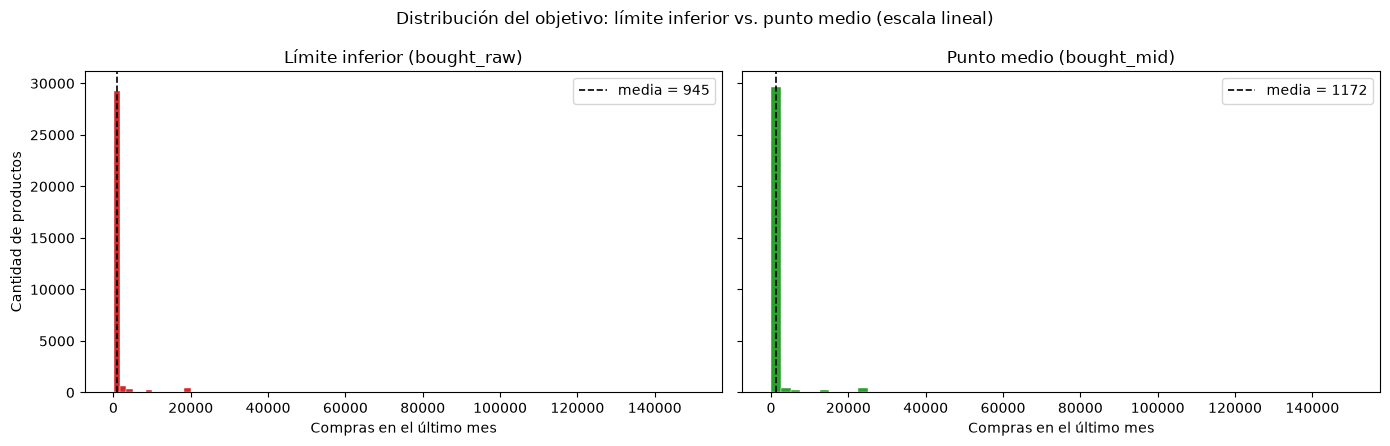

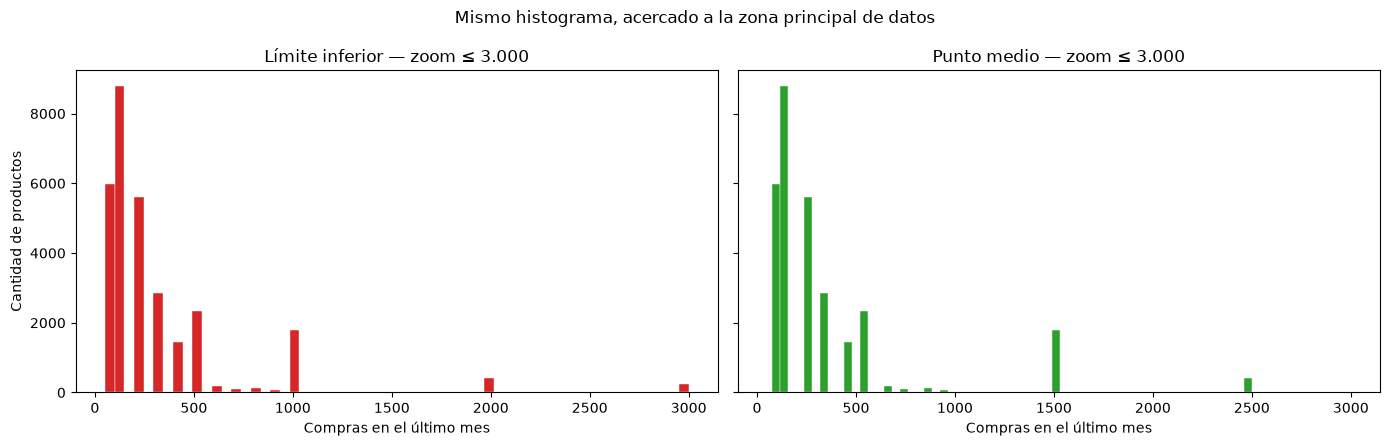

,limite_inferior,punto_medio
count,31202.000000,31202.000000
mean,944.867316,1171.992981
std,4941.157670,5944.714780
min,50.000000,75.000000
25%,100.000000,150.000000
50%,200.000000,250.000000
75%,400.000000,450.000000
max,100000.000000,150000.000000


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True, sharey=True)
bins_hist = 60

axes[0].hist(df["bought_raw"], bins=bins_hist, color="#d62728", edgecolor="white", linewidth=0.3)
axes[0].set_title("Límite inferior (bought_raw)")
axes[0].set_xlabel("Compras en el último mes")
axes[0].set_ylabel("Cantidad de productos")
axes[0].axvline(df["bought_raw"].mean(), color="black", ls="--", lw=1.2,
                label=f"media = {df['bought_raw'].mean():.0f}")
axes[0].legend()

axes[1].hist(df["bought_mid"], bins=bins_hist, color="#2ca02c", edgecolor="white", linewidth=0.3)
axes[1].set_title("Punto medio (bought_mid)")
axes[1].set_xlabel("Compras en el último mes")
axes[1].axvline(df["bought_mid"].mean(), color="black", ls="--", lw=1.2,
                label=f"media = {df['bought_mid'].mean():.0f}")
axes[1].legend()

plt.suptitle("Distribución del objetivo: límite inferior vs. punto medio (escala lineal)", fontsize=12)
plt.tight_layout()
plt.show()

# Version recortada hasta 3.000 compras para ver la zona donde se concentran los datos
recorte = 3000
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True, sharey=True)
axes[0].hist(df.loc[df["bought_raw"] <= recorte, "bought_raw"], bins=60,
             color="#d62728", edgecolor="white", linewidth=0.3)
axes[0].set_title("Límite inferior — zoom ≤ 3.000")
axes[0].set_xlabel("Compras en el último mes")
axes[0].set_ylabel("Cantidad de productos")

axes[1].hist(df.loc[df["bought_mid"] <= recorte, "bought_mid"], bins=60,
             color="#2ca02c", edgecolor="white", linewidth=0.3)
axes[1].set_title("Punto medio — zoom ≤ 3.000")
axes[1].set_xlabel("Compras en el último mes")

plt.suptitle("Mismo histograma, acercado a la zona principal de datos", fontsize=12)
plt.tight_layout()
plt.show()

resumen = pd.DataFrame({
    "limite_inferior": df["bought_raw"].describe(),
    "punto_medio": df["bought_mid"].describe(),
})
resumen

## 3. Variables excluidas

| Variable | Por qué se excluye |
|---|---|
| `image_url` | Identificador CDN de imagen; sin valor predictivo. |
| `product_url` | URL con tokens de sesión; identificador, no feature. |
| `collected_at` | Timestamp de recolección del scraping; no aporta señal. |
| `Price_on_variant` | ~50 % nulos y muchas entradas son descriptores (`basic variant price: 16 Count`), no precios. |

In [14]:
excluidas = {
    "image_url": "Identificador CDN sin valor predictivo",
    "product_url": "URL con token de sesion; identificador, no feature",
    "collected_at": "Timestamp de recoleccion; no aporta senal del producto",
    "Price_on_variant": "~50% nulos + entradas descriptivas no numericas",
}
for c, j in excluidas.items():
    print(f"- {c}: {j}")
df = df.drop(columns=list(excluidas.keys()))

- image_url: Identificador CDN sin valor predictivo
- product_url: URL con token de sesion; identificador, no feature
- collected_at: Timestamp de recoleccion; no aporta senal del producto
- Price_on_variant: ~50% nulos + entradas descriptivas no numericas


## 4. `Rating`

Se extrae el número de `"4.6 out of 5 stars"`. Los nulos se imputan con la **mediana**
(robusta a extremos); la media sesgaría con los productos muy mal calificados.

In [15]:
nulos_rating = df["Rating"].isna().sum()
df["Rating"] = df["Rating"].astype(str).str.extract(r"([\d.]+)")[0].astype(float)
mediana_rating = df["Rating"].median()
df["Rating"] = df["Rating"].fillna(mediana_rating)
print(f"Nulos de Rating imputados con mediana ({mediana_rating:.2f}): {nulos_rating}")

Nulos de Rating imputados con mediana (4.50): 76


## 5. Numéricas: reseñas y precio

- **`Number_of_reviews`**: se quitan comas y se convierte a numérico. Nulos → **0** (un producto
  sin reseñas registradas *significa* cero reseñas).
- **`Current/discounted_price`** → `current_price`: se quitan comas y se convierte a numérico.
  **Aqui NO se imputa**: se dejan los `NaN` para que cada variante de dataset decida
  si elimina esas filas o las imputa (ver seccion 10).

**Atípicos del precio:** se **marcan** con `is_price_outlier` (IQR) pero **NO se eliminan**.
El precio es *feature*, no objetivo: un producto caro es legítimo. El IQR se calcula sobre los
valores no nulos; las filas con precio nulo reciben la bandera `-1` (sin evaluar) y luego se
resuelven en la construccion de cada variante.


In [16]:
df["Number_of_reviews"] = df["Number_of_reviews"].astype(str).str.replace(",", "", regex=False)
df["Number_of_reviews"] = pd.to_numeric(df["Number_of_reviews"], errors="coerce")
n_rev_na = df["Number_of_reviews"].isna().sum()
df["Number_of_reviews"] = df["Number_of_reviews"].fillna(0)
print(f"Number_of_reviews: nulos imputados con 0: {n_rev_na}")

# Precio: SOLO se parsea. Los nulos se dejan como NaN (cada variante decide).
precio = df["Current/discounted_price"].astype(str).str.replace(",", "", regex=False)
precio = pd.to_numeric(precio, errors="coerce")
df["current_price"] = precio
nulos_precio = precio.isna().sum()
print(f"Precio: nulos conservados (sin imputar): {nulos_precio} "
    f"({nulos_precio / len(df) * 100:.2f}%)")

# IQR sobre los valores NO nulos (bandera; no se elimina nada).
Q1, Q3 = precio.quantile([0.25, 0.75])
IQR = Q3 - Q1
lb, ub = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
df["is_price_outlier"] = ((precio < lb) | (precio > ub)).astype(int)

print(f"Precio: Q1={Q1:.2f} Q3={Q3:.2f} IQR={IQR:.2f} bounds=[{lb:.2f},{ub:.2f}]")
print(f"Outliers precio marcados (no eliminados): {df['is_price_outlier'].sum()} "
    f"({df['is_price_outlier'].mean() * 100:.2f}%)")


Number_of_reviews: nulos imputados con 0: 76
Precio: nulos conservados (sin imputar): 6766 (21.68%)
Precio: Q1=24.99 Q3=159.95 IQR=134.96 bounds=[-177.45,362.39]
Outliers precio marcados (no eliminados): 2405 (7.71%)


## 6. Banderas y categóricas

- `has_discount`: `1` si `Listed_price != "No Discount"`.
- `is_best_seller_flag`: la columna original tiene **8 categorías**; se codifica `1` solo para `Best Seller`.
- `is_sponsored_flag`, `has_coupon`: banderas directas.
- **`buy_box_status`**: 3 niveles, porque la **ausencia** de dato se modela como categoría
  propia (`unknown`) y no se colapsa con "no comprable".

In [17]:
df["has_discount"] = (df["Listed_price"] != "No Discount").astype(int)
df["is_best_seller_flag"] = (df["is_best_seller"] == "Best Seller").astype(int)
df["is_sponsored_flag"] = (df["is_sponsored"] == "Sponsored").astype(int)
df["has_coupon"] = (df["is_couponed"] != "No Coupon").astype(int)

def buy_box_cat(x):
    if pd.isna(x):
        return "unknown"
    return "add_to_cart" if x == "Add to cart" else "no_buy_box"

df["buy_box_status"] = df["buy_box_availability"].apply(buy_box_cat)
print("buy_box_status (3 niveles):")
print(df["buy_box_status"].value_counts().to_string())

buy_box_status (3 niveles):
buy_box_status
add_to_cart    22701
unknown         8501


## 7. `sustainability_badges`: prueba de asociación

Con **~91 % de nulos** la variable cubre muy poco. Antes de retenerla se hace una
**prueba χ² de homogeneidad** (con badge vs. sin badge) contra la categoría del objetivo
y se mide el tamaño de efecto con **Cramér's V**.

**Advertencia:** el nombre de la columna es impreciso. Mezcla insignias de sostenibilidad
reales (Small Business, Carbon impact, Energy efficiency…) con badges de compatibilidad
(`Works with Alexa`, `Alexa Built-in`), que no son sostenibilidad.


In [18]:
n_sust_nulos = df["sustainability_badges"].isna().sum()
print(f"sustainability_badges: nulos = {n_sust_nulos} ({n_sust_nulos / len(df) * 100:.1f}%)")

sub = df[df["sustainability_badges"].notna()]
resto = df[df["sustainability_badges"].isna()]
cats = labels
fila_sub = sub["bought_cat"].value_counts().reindex(cats, fill_value=0).values
fila_resto = resto["bought_cat"].value_counts().reindex(cats, fill_value=0).values
tab_cat = np.array([fila_sub, fila_resto])

chi2, p, dof, expected = chi2_contingency(tab_cat)
n = tab_cat.sum()
cramers_v = np.sqrt(chi2 / (n * (min(tab_cat.shape) - 1)))

print("Tabla de contingencia (con badge / sin badge) x categoria:")
print(pd.DataFrame(tab_cat, index=["con_badge", "sin_badge"], columns=cats).to_string())
print(f"Chi2 homogeneidad: chi2={chi2:.2f} p={p:.4f} dof={dof} Cramer's V={cramers_v:.4f}")

if p >= 0.05 or cramers_v < 0.1:
    print("-> Sin asociacion significativa / efecto trivial. DECISION: ELIMINAR.")
    eliminar_sust = True
else:
    print("-> Asociacion significativa. DECISION: RETENER (nombre original, Opcion C).")
    eliminar_sust = False

df["has_sustainability_badge"] = df["sustainability_badges"].notna().astype(int)

sustainability_badges: nulos = 28460 (91.2%)
Tabla de contingencia (con badge / sin badge) x categoria:
           50-100  101-200  201-500  >500
con_badge     406      582      815   939
sin_badge    5561     8219     9064  5616
Chi2 homogeneidad: chi2=335.53 p=0.0000 dof=3 Cramer's V=0.1037
-> Asociacion significativa. DECISION: RETENER (nombre original, Opcion C).


## 8. `Title` y `delivery_details`

- `title_word_count`: número de palabras del título (proxy de "riqueza" del listing).
- `delivery_details`: se separa en:
  - `is_free_delivery`: `1` si la cadena contiene `FREE`.
  - `delivery_cost`: costo extraído de `$X delivery`.
  - **Corrección clave:** si el envío es gratis, el costo se fija en **0** (gratis real),
    para no confundir "gratis" con "desconocido".
  - **Aqui NO se imputa la mediana**: los que quedan desconocidos se dejan como `NaN` y
    cada variante decide si imputa con 0 o descarta la columna (ver sección 10).


In [19]:
df["title_word_count"] = df["Title"].astype(str).str.split().str.len()
print(f"title_word_count: min={df['title_word_count'].min()} media={df['title_word_count'].mean():.1f}")

col = df["delivery_details"].fillna("").astype(str).str.strip()
df["is_free_delivery"] = col.str.contains("FREE", case=False).astype(int)
costo = pd.to_numeric(col.str.extract(r"\$\s*([\d]+(?:\.\d+)?)\s*delivery")[0], errors="coerce")
# Gratis -> 0 real; el resto que no trae numero queda como NaN (se resuelve por variante).
df["delivery_cost"] = np.where(df["is_free_delivery"] == 1, 0, costo)
df["delivery_cost"] = pd.to_numeric(df["delivery_cost"], errors="coerce")

nulos_costo = df["delivery_cost"].isna().sum()
print(f"is_free_delivery=1: {df['is_free_delivery'].sum()}")
print(f"delivery_cost: desconocidos conservados como NaN (sin imputar): {nulos_costo}")


title_word_count: min=2 media=20.7
is_free_delivery=1: 6236
delivery_cost: desconocidos conservados como NaN (sin imputar): 24560


## 9. Transformación logarítmica

Se aplica `log1p` a las numéricas y, sobre todo, al **objetivo**. El log comprime la cola
derecha, estabiliza la varianza y evita que el modelo se obsesione con los pocos productos
virales. Al predecir, se des-transforma con `expm1`.

In [20]:
df["log_price"] = np.log1p(df["current_price"])
df["log_reviews"] = np.log1p(df["Number_of_reviews"])
df["log_bought"] = np.log1p(df["bought_in_last_month"])
df["log_delivery_cost"] = np.log1p(df["delivery_cost"])
df["log_title_words"] = np.log1p(df["title_word_count"])

df[["log_price", "log_reviews", "log_bought", "log_delivery_cost", "log_title_words"]].describe().T

,count,mean,std,min,25%,50%,75%,max
log_price,24436.0,4.270004,1.223877,1.249902,3.257712,4.288951,5.081094,8.342602
log_reviews,31202.0,6.402599,2.048829,0.000000,4.912655,6.498282,7.829531,13.671177
log_bought,31202.0,5.605212,1.193463,4.330733,5.017280,5.525453,6.111467,11.918397
log_delivery_cost,6642.0,0.233035,0.919565,0.000000,0.000000,0.000000,0.000000,5.429433
log_title_words,31202.0,2.972220,0.493779,1.098612,2.639057,3.178054,3.332205,3.828641


## 10. Generación de los 4 datasets para comparar estrategias de limpieza

Hasta aquí el dataset está limpio salvo **dos decisiones abiertas**:

1. Qué hacer con los productos **sin precio** (`current_price` nulo).
2. Qué hacer con el **costo de envío desconocido** (`delivery_cost` nulo).

En vez de decidirlo a ciegas, generamos un **diseño 2×2** de variantes y luego
entrenaremos modelos sobre cada una para ver cuál es la mejor opción:

| # | Precio vacío | `delivery` |
|---|---|---|
| **v1** | **Eliminar fila** | imputar costo con 0 |
| **v2** | **Eliminar fila** | **sin columna** `delivery_cost` |
| **v3** | **Imputar mediana** | imputar costo con 0 |
| **v4** | **Imputar mediana** | **sin columna** `delivery_cost` |

Todas parten del **mismo** `df` (pipeline idéntico hasta aquí). La única diferencia es cómo
se resuelven el precio y el delivery. Se exportan a `dataset_v1.csv` … `dataset_v4.csv`.


In [21]:
# Columnas comunes a todas las variantes
BASE_COLS = [
    "Rating", "Number_of_reviews", "has_discount", "is_best_seller_flag",
    "is_sponsored_flag", "has_coupon", "buy_box_status", "is_free_delivery",
    "title_word_count", "has_sustainability_badge",
    "bought_in_last_month", "bought_cat",
]

def build_variant(precio_accion, delivery_accion):
    """Construye una variante a partir del df comun.
       precio_accion:   'eliminar' | 'imputar'
       delivery_accion: 'imputar'  | 'quitar'
    """
    d = df.copy()

    # --- Precio ---
    if precio_accion == "eliminar":
        d = d[d["current_price"].notna()].copy()
    else:  # imputar
        d["current_price"] = d["current_price"].fillna(d["current_price"].median())

    # Bandera de atipicos (IQR) recalculada sobre la variante
    Q1, Q3 = d["current_price"].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lb, ub = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    d["is_price_outlier"] = ((d["current_price"] < lb) | (d["current_price"] > ub)).astype(int)

    cols = BASE_COLS.copy()

    # --- Delivery ---
    if delivery_accion == "imputar":
        d["delivery_cost"] = d["delivery_cost"].fillna(0)   # imputar con 0
        cols += ["delivery_cost"]
    # 'quitar': se omite delivery_cost (is_free_delivery SI se conserva)

    cols += ["current_price", "is_price_outlier"]

    # --- Transformacion log ---
    d["log_price"] = np.log1p(d["current_price"])
    d["log_reviews"] = np.log1p(d["Number_of_reviews"])
    d["log_bought"] = np.log1p(d["bought_in_last_month"])
    d["log_title_words"] = np.log1p(d["title_word_count"])
    cols += ["log_price", "log_reviews", "log_bought", "log_title_words"]

    if delivery_accion == "imputar":
        d["log_delivery_cost"] = np.log1p(d["delivery_cost"])
        cols += ["log_delivery_cost"]

    return d[cols].copy()


In [22]:
# Definicion de las 4 variantes
variantes = {
    1: ("eliminar", "imputar"),
    2: ("eliminar", "quitar"),
    3: ("imputar",  "imputar"),
    4: ("imputar",  "quitar"),
}

datasets = {}
resumen = []

for vid, (p_acc, d_acc) in variantes.items():
    d = build_variant(p_acc, d_acc)
    datasets[vid] = d
    nombre = f"dataset_v{vid}.csv"
    d.to_csv(nombre, index=False)
    resumen.append({
        "variante": vid,
        "precio": p_acc,
        "delivery": d_acc,
        "filas": len(d),
        "columnas": d.shape[1],
        "tiene_delivery_cost": "delivery_cost" in d.columns,
        "nulos": int(d.isna().sum().sum()),
    })
    print(f"v{vid} [{p_acc:>8} | {d_acc:>8}] -> {nombre}  "
        f"filas={len(d)}  columnas={d.shape[1]}")

pd.DataFrame(resumen)

v1 [eliminar |  imputar] -> dataset_v1.csv  filas=24436  columnas=20
v2 [eliminar |   quitar] -> dataset_v2.csv  filas=24436  columnas=18
v3 [ imputar |  imputar] -> dataset_v3.csv  filas=31202  columnas=20
v4 [ imputar |   quitar] -> dataset_v4.csv  filas=31202  columnas=18


,variante,precio,delivery,filas,columnas,tiene_delivery_cost,nulos
0,1,eliminar,imputar,24436,20,True,0
1,2,eliminar,quitar,24436,18,False,0
2,3,imputar,imputar,31202,20,True,0
3,4,imputar,quitar,31202,18,False,0


In [23]:
# Comparacion de columnas entre variantes
for vid in variantes:
    cols = list(datasets[vid].columns)
    print(f"=== v{vid} ({len(cols)} columnas) ===")
    print(cols)
    print()


=== v1 (20 columnas) ===
['Rating', 'Number_of_reviews', 'has_discount', 'is_best_seller_flag', 'is_sponsored_flag', 'has_coupon', 'buy_box_status', 'is_free_delivery', 'title_word_count', 'has_sustainability_badge', 'bought_in_last_month', 'bought_cat', 'delivery_cost', 'current_price', 'is_price_outlier', 'log_price', 'log_reviews', 'log_bought', 'log_title_words', 'log_delivery_cost']

=== v2 (18 columnas) ===
['Rating', 'Number_of_reviews', 'has_discount', 'is_best_seller_flag', 'is_sponsored_flag', 'has_coupon', 'buy_box_status', 'is_free_delivery', 'title_word_count', 'has_sustainability_badge', 'bought_in_last_month', 'bought_cat', 'current_price', 'is_price_outlier', 'log_price', 'log_reviews', 'log_bought', 'log_title_words']

=== v3 (20 columnas) ===
['Rating', 'Number_of_reviews', 'has_discount', 'is_best_seller_flag', 'is_sponsored_flag', 'has_coupon', 'buy_box_status', 'is_free_delivery', 'title_word_count', 'has_sustainability_badge', 'bought_in_last_month', 'bought_cat',

## 11. Vista previa: `.head(9)` de cada dataset

Se muestran las primeras 9 filas de cada variante para inspeccionar que las columnas,
tipos y valores quedaron correctos. Nótese que las variantes sin delivery (v2, v4) tienen
dos columnas menos (`delivery_cost` y `log_delivery_cost`).


In [24]:
# Primeras 9 filas de cada dataset generado
for vid in variantes:
    print(f"\n{'=' * 80}")
    print(f"DATASET v{vid}  ({datasets[vid].shape[0]} filas x {datasets[vid].shape[1]} columnas)")
    print('=' * 80)
    display(datasets[vid].head(9))



DATASET v1  (24436 filas x 20 columnas)


,Rating,Number_of_reviews,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,buy_box_status,is_free_delivery,title_word_count,has_sustainability_badge,bought_in_last_month,bought_cat,delivery_cost,current_price,is_price_outlier,log_price,log_reviews,log_bought,log_title_words,log_delivery_cost
0,4.6,375.0,1,0,1,1,add_to_cart,0,30,1,350.0,201-500,0.0,89.68,0,4.507337,5.929589,5.860786,3.433987,0.0
1,4.3,2457.0,1,0,1,0,add_to_cart,0,34,0,6500.0,>500,0.0,9.99,0,2.396986,7.807103,8.779711,3.555348,0.0
2,4.6,3044.0,1,0,1,0,add_to_cart,0,29,0,2500.0,>500,0.0,314.00,0,5.752573,8.021256,7.824446,3.401197,0.0
10,4.7,865598.0,0,1,0,0,add_to_cart,0,12,1,150000.0,>500,0.0,14.99,0,2.771964,13.671177,11.918397,2.564949,0.0
12,4.2,152.0,0,0,1,0,add_to_cart,0,30,0,150.0,101-200,0.0,29.99,0,3.433665,5.030438,5.017280,3.433987,0.0
13,4.4,12076.0,0,0,1,0,add_to_cart,0,24,0,1500.0,>500,0.0,249.99,0,5.525413,9.399058,7.313887,3.218876,0.0
14,4.7,7235.0,0,0,1,0,add_to_cart,0,30,1,550.0,>500,0.0,69.95,0,4.261975,8.886824,6.311735,3.433987,0.0
16,4.8,198512.0,0,1,0,0,add_to_cart,0,19,1,85000.0,>500,0.0,39.97,0,3.712840,12.198610,11.350418,2.995732,0.0
17,4.7,625776.0,0,1,0,0,add_to_cart,0,16,1,150000.0,>500,0.0,14.49,0,2.740195,13.346749,11.918397,2.833213,0.0



DATASET v2  (24436 filas x 18 columnas)


,Rating,Number_of_reviews,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,buy_box_status,is_free_delivery,title_word_count,has_sustainability_badge,bought_in_last_month,bought_cat,current_price,is_price_outlier,log_price,log_reviews,log_bought,log_title_words
0,4.6,375.0,1,0,1,1,add_to_cart,0,30,1,350.0,201-500,89.68,0,4.507337,5.929589,5.860786,3.433987
1,4.3,2457.0,1,0,1,0,add_to_cart,0,34,0,6500.0,>500,9.99,0,2.396986,7.807103,8.779711,3.555348
2,4.6,3044.0,1,0,1,0,add_to_cart,0,29,0,2500.0,>500,314.00,0,5.752573,8.021256,7.824446,3.401197
10,4.7,865598.0,0,1,0,0,add_to_cart,0,12,1,150000.0,>500,14.99,0,2.771964,13.671177,11.918397,2.564949
12,4.2,152.0,0,0,1,0,add_to_cart,0,30,0,150.0,101-200,29.99,0,3.433665,5.030438,5.017280,3.433987
13,4.4,12076.0,0,0,1,0,add_to_cart,0,24,0,1500.0,>500,249.99,0,5.525413,9.399058,7.313887,3.218876
14,4.7,7235.0,0,0,1,0,add_to_cart,0,30,1,550.0,>500,69.95,0,4.261975,8.886824,6.311735,3.433987
16,4.8,198512.0,0,1,0,0,add_to_cart,0,19,1,85000.0,>500,39.97,0,3.712840,12.198610,11.350418,2.995732
17,4.7,625776.0,0,1,0,0,add_to_cart,0,16,1,150000.0,>500,14.49,0,2.740195,13.346749,11.918397,2.833213



DATASET v3  (31202 filas x 20 columnas)


,Rating,Number_of_reviews,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,buy_box_status,is_free_delivery,title_word_count,has_sustainability_badge,bought_in_last_month,bought_cat,delivery_cost,current_price,is_price_outlier,log_price,log_reviews,log_bought,log_title_words,log_delivery_cost
0,4.6,375.0,1,0,1,1,add_to_cart,0,30,1,350.0,201-500,0.0,89.68,0,4.507337,5.929589,5.860786,3.433987,0.0
1,4.3,2457.0,1,0,1,0,add_to_cart,0,34,0,6500.0,>500,0.0,9.99,0,2.396986,7.807103,8.779711,3.555348,0.0
2,4.6,3044.0,1,0,1,0,add_to_cart,0,29,0,2500.0,>500,0.0,314.00,1,5.752573,8.021256,7.824446,3.401197,0.0
3,4.6,35882.0,0,1,0,0,unknown,0,24,0,15000.0,>500,0.0,71.89,0,4.288951,10.488019,9.615872,3.218876,0.0
4,4.8,28988.0,0,0,0,0,unknown,0,24,0,15000.0,>500,0.0,71.89,0,4.288951,10.274672,9.615872,3.218876,0.0
5,4.6,44522.0,0,1,0,0,unknown,0,9,0,150000.0,>500,0.0,71.89,0,4.288951,10.703761,11.918397,2.302585,0.0
6,4.5,13466.0,0,0,0,0,unknown,0,30,0,15000.0,>500,0.0,71.89,0,4.288951,9.507998,9.615872,3.433987,0.0
7,4.6,38105.0,0,1,0,0,unknown,0,22,0,15000.0,>500,0.0,71.89,0,4.288951,10.548127,9.615872,3.135494,0.0
9,4.7,7308.0,0,1,0,0,unknown,0,24,1,15000.0,>500,0.0,71.89,0,4.288951,8.896862,9.615872,3.218876,0.0



DATASET v4  (31202 filas x 18 columnas)


,Rating,Number_of_reviews,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,buy_box_status,is_free_delivery,title_word_count,has_sustainability_badge,bought_in_last_month,bought_cat,current_price,is_price_outlier,log_price,log_reviews,log_bought,log_title_words
0,4.6,375.0,1,0,1,1,add_to_cart,0,30,1,350.0,201-500,89.68,0,4.507337,5.929589,5.860786,3.433987
1,4.3,2457.0,1,0,1,0,add_to_cart,0,34,0,6500.0,>500,9.99,0,2.396986,7.807103,8.779711,3.555348
2,4.6,3044.0,1,0,1,0,add_to_cart,0,29,0,2500.0,>500,314.00,1,5.752573,8.021256,7.824446,3.401197
3,4.6,35882.0,0,1,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.488019,9.615872,3.218876
4,4.8,28988.0,0,0,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.274672,9.615872,3.218876
5,4.6,44522.0,0,1,0,0,unknown,0,9,0,150000.0,>500,71.89,0,4.288951,10.703761,11.918397,2.302585
6,4.5,13466.0,0,0,0,0,unknown,0,30,0,15000.0,>500,71.89,0,4.288951,9.507998,9.615872,3.433987
7,4.6,38105.0,0,1,0,0,unknown,0,22,0,15000.0,>500,71.89,0,4.288951,10.548127,9.615872,3.135494
9,4.7,7308.0,0,1,0,0,unknown,0,24,1,15000.0,>500,71.89,0,4.288951,8.896862,9.615872,3.218876


---
**Fin del pipeline.** Se generaron 4 datasets (`dataset_v1.csv` … `dataset_v4.csv`) con el
mismo pipeline de limpieza y solo dos decisiones variando (precio y delivery).
En la fase de modelado se comparará cuál da mejor rendimiento.

El resumen de decisiones está en `LIMPIEZA_DATOS.md`.
